# Native Sparse Attention, part 3: the sliding window and branch isolation
*Companion notebooks to Yuan et al., 2025, [Native Sparse Attention](https://arxiv.org/abs/2502.11089). Part 3 of 7.*

**TL;DR.** The third branch is the simplest: each query attends to the last `w` tokens, at full resolution, and nothing else (`w = 512` in the paper). It exists for a reason that is about *training dynamics*, not about information: Yuan et al. argue that local patterns are learned faster than long-range ones and, if they share keys and values with the other branches, **shortcut** the learning of compression and selection. So NSA gives each branch its **own keys and values** and mixes the outputs with gates (part 4). Here we build the window, prove it is local and causal, and show what "isolated" means in code. The shortcut claim itself is a training-dynamics claim, so we test it in part 6 rather than assert it here.

<img src="nsa_assets/fig2_architecture.png" width="700"/>

*Figure 2 of the paper. The window branch (right-most path) has the sparsest-looking mask of the three: a thin band along the diagonal. Notice it is the only branch where the key set is the same for every query up to a shift.*

In [1]:
import math, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"   # used only where a notebook trains
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
CMP_C, SLC_C, WIN_C, FULL_C = "#1c7ed6", "#d9480f", "#2f9e44", "#495057"      # one colour per branch, used in every notebook
NEG = -1e30                                                                     # a finite "minus infinity": a fully masked row gives uniform weights, never NaN

CHECKS = []
def check(name, ok, detail=""):
    """Record + print PASS/FAIL. Every claim in these notebooks is backed by one of these lines."""
    CHECKS.append((name, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))

In [2]:
def full_causal_attention(q, k, v):
    """Ordinary causal attention, with the grouped-query layout NSA uses.
    q: (B, G, H, T, dk)   G key/value groups, H query heads share each group's K and V (GQA)
    k: (B, G, T, dk)      v: (B, G, T, dv)       returns (output (B,G,H,T,dv), weights (B,G,H,T,T))"""
    T, dk = q.shape[-2], q.shape[-1]
    scores = torch.einsum("bghtd,bgsd->bghts", q, k) / math.sqrt(dk)          # how much query t likes key s
    causal = torch.ones(T, T, dtype=torch.bool, device=q.device).tril()        # token t may only look at tokens <= t
    p = scores.masked_fill(~causal, NEG).softmax(-1)                           # each row sums to 1
    return torch.einsum("bghts,bgsd->bghtd", p, v), p

## Attending to the last w tokens

For a query at position `t`, the window holds tokens `t-w+1 ... t`. A concrete case: with `w = 4`, token 9 sees tokens 6, 7, 8, 9; token 2 sees tokens 0, 1, 2 (there is nothing before the start). In the attention matrix this is a band of width `w` along the diagonal.

token 9 sees: [6, 7, 8, 9]    token 2 sees: [0, 1, 2]
PASS  every query sees at most w tokens


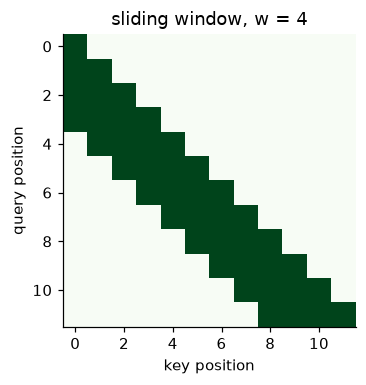

In [3]:
T, w = 12, 4
band = torch.zeros(T, T, dtype=torch.bool)
for t in range(T): band[t, max(0, t - w + 1): t + 1] = True
print("token 9 sees:", band[9].nonzero().flatten().tolist(), "   token 2 sees:", band[2].nonzero().flatten().tolist())
check("every query sees at most w tokens", band.sum(1).max().item() == w)
fig, ax = plt.subplots(figsize=(4, 3.6)); ax.imshow(band, cmap="Greens", origin="upper"); ax.set_xlabel("key position"); ax.set_ylabel("query position"); ax.set_title("sliding window, w = 4"); ax.grid(False); plt.tight_layout(); plt.show()

In [4]:
def window_attention(q, k, v, w):
    """Attend only to the last w tokens (including the current one)."""
    B, G, T, dk = k.shape
    kw = F.pad(k, (0, 0, w - 1, 0)).unfold(2, w, 1).transpose(-1, -2)          # (B,G,T,w,dk): window of every position
    vw = F.pad(v, (0, 0, w - 1, 0)).unfold(2, w, 1).transpose(-1, -2)
    pos = torch.arange(T, device=k.device)[:, None] - (w - 1) + torch.arange(w, device=k.device)[None, :]
    valid = (pos >= 0)[None, None, None]                                         # the left padding is not a real token
    s = torch.einsum("bghtd,bgtwd->bghtw", q, kw) / math.sqrt(dk)
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid
    return torch.einsum("bghtw,bgtwd->bghtd", p, vw)

Our `window_attention` does not build the T x T matrix: it slices a `(T, w)` stack of recent keys (with `unfold`) so memory and work are `T * w`, not `T * T`. To trust it, we compare with ordinary attention under a band mask, and then check locality by scrambling a token that is *outside* the window.

In [5]:
torch.manual_seed(0)
B, G, H, T, dk, w = 1, 1, 2, 64, 16, 8
q, k, v = torch.randn(B, G, H, T, dk), torch.randn(B, G, T, dk), torch.randn(B, G, T, dk)
out = window_attention(q, k, v, w)

s = torch.einsum("bghtd,bgsd->bghts", q, k) / math.sqrt(dk)                    # reference: full scores with a band mask
tt, ss = torch.arange(T)[:, None], torch.arange(T)[None, :]
mask = (ss <= tt) & (ss > tt - w)
ref = torch.einsum("bghts,bgsd->bghtd", s.masked_fill(~mask, NEG).softmax(-1), v)
check("window attention equals full attention under a band mask", torch.allclose(out, ref, atol=1e-5), f"max diff {(out - ref).abs().max():.1e}")

k2, v2 = k.clone(), v.clone(); k2[:, :, 10] += 5.0; v2[:, :, 10] += 5.0         # change token 10
out2 = window_attention(q, k2, v2, w)
changed = ((out - out2).abs().amax(dim=(0, 1, 2, 4)) > 1e-6).nonzero().flatten().tolist()
print("queries whose output changed when token 10 changed:", changed)
check("only queries 10 ... 10+w-1 can see token 10", changed == list(range(10, 10 + w)))
check("the first query sees only itself (left padding is not a real token)", torch.allclose(out[..., 0, :], v[:, :, None, 0].expand(B, G, H, dk), atol=1e-5))

PASS  window attention equals full attention under a band mask   [max diff 2.4e-07]
queries whose output changed when token 10 changed: [10, 11, 12, 13, 14, 15, 16, 17]
PASS  only queries 10 ... 10+w-1 can see token 10
PASS  the first query sees only itself (left padding is not a real token)


## What the window cannot do

A window of `w` tokens is blind beyond `w`. That sounds trivial, but it is the whole reason the other two branches exist, so we make it concrete: change a token **far** from the query and the window branch's output does not move at all, no matter how important that token is. Whatever long-range information NSA has must therefore come through compression and selection.

In [6]:
t_query, far = 60, 5                                              # query at 60, token 5 is 55 positions away (> w = 8)
k3, v3 = k.clone(), v.clone(); k3[:, :, far] += 100.0; v3[:, :, far] += 100.0
d_win = (window_attention(q, k3, v3, w)[..., t_query, :] - out[..., t_query, :]).abs().max().item()
d_full = (full_causal_attention(q, k3, v3)[0][..., t_query, :] - full_causal_attention(q, k, v)[0][..., t_query, :]).abs().max().item()
print(f"effect of a huge change at distance {t_query - far}:  window branch {d_win:.1e}   full attention {d_full:.1e}")
check("a far token has exactly zero influence on the window branch", d_win == 0.0)
check("the same far token does move full attention", d_full > 1e-3)

effect of a huge change at distance 55:  window branch 0.0e+00   full attention 1.5e-02
PASS  a far token has exactly zero influence on the window branch
PASS  the same far token does move full attention


## Why a separate branch with its own keys and values

Yuan et al.'s argument, in their words from section 3.3.3: *local patterns typically adapt faster and can dominate the learning process, potentially preventing the model from effectively learning from compression and selection tokens.* Their remedy has two parts: a dedicated window branch, and **independent keys and values for the three branches**, so that gradients from the easy local signal cannot flow into the keys and values the long-range branches rely on. It "introduces minimal overhead" because the extra cost is three small projections instead of one.

In code, "independent" is only a matter of which linear layers are used. Our `NSALayer` (built in full in part 4) has a flag for it:

(The next cell pulls in the compression, selection and layer code built in parts 1, 2 and 4, only so that we can count parameters. Part 4 explains the layer.)

In [7]:
class Compressor(nn.Module):
    """Squeeze every block of `l` consecutive keys (or values) into ONE vector.
    Blocks start every `d` tokens; d < l means neighbouring blocks overlap (paper: l=32, d=16).
    phi = learnable position embedding inside the block -> flatten -> small MLP."""
    def __init__(self, dim, l, d):
        super().__init__(); self.l, self.d = l, d
        self.pos = nn.Parameter(torch.zeros(l, dim))                           # intra-block position encoding
        self.mlp = nn.Sequential(nn.Linear(l * dim, dim), nn.GELU(), nn.Linear(dim, dim))
        nn.init.zeros_(self.mlp[2].weight); nn.init.zeros_(self.mlp[2].bias)   # our choice: start as plain mean-pooling, learn a correction
    def forward(self, x):                                                      # x: (B, G, T, dim)
        blocks = x.unfold(2, self.l, self.d).transpose(-1, -2)                 # (B, G, Nc, l, dim): the overlapping blocks
        return blocks.mean(-2) + self.mlp((blocks + self.pos).flatten(-2))     # (B, G, Nc, dim)   mean-pool + learned phi

def n_compressed(T, l, d): return (T - l) // d + 1

def compressed_valid(T, l, d, device="cpu"):
    """(T, Nc) bool. Compressed block j covers tokens [j*d, j*d + l). Query t may use it only if ALL of its
    tokens are <= t (otherwise the block would leak the future)."""
    j = torch.arange(n_compressed(T, l, d), device=device); t = torch.arange(T, device=device)
    return (j[None, :] * d + l - 1) <= t[:, None]

def compressed_attention(q, k_cmp, v_cmp, valid):
    """q (B,G,H,T,dk) attends to the compressed keys. Returns (output, attention weights p_cmp (B,G,H,T,Nc))."""
    s = torch.einsum("bghtd,bgcd->bghtc", q, k_cmp) / math.sqrt(q.shape[-1])
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid                          # zero out invalid blocks (and empty rows)
    return torch.einsum("bghtc,bgcd->bghtd", p, v_cmp), p

In [8]:
def overlap_matrix(T, l, d, lp, device="cpu"):
    """M[i, j] = number of tokens shared by compressed block i and selection block j (size lp).
    p_slc = p_cmp @ M turns 'which compressed blocks does the query like' into 'which selection blocks look important'."""
    Nc, Ns = n_compressed(T, l, d), T // lp
    M = torch.zeros(Nc, Ns)
    for i in range(Nc):
        a, b = i * d, i * d + l
        for j in range(Ns): M[i, j] = max(0, min(b, (j + 1) * lp) - max(a, j * lp))
    return (M / d).to(device)

def minmax_block_scores(q, k, lp):
    """Quest-style heuristic (NO learned parameters): upper-bound each block's best dot product from per-channel min/max of its keys."""
    B, G, T, dk = k.shape; kb = k.view(B, G, T // lp, lp, dk)
    kmin, kmax = kb.min(3).values, kb.max(3).values                             # (B,G,Ns,dk)
    qq = q.unsqueeze(-2)                                                       # (B,G,H,T,1,dk)
    return torch.maximum(qq * kmin[:, :, None, None], qq * kmax[:, :, None, None]).sum(-1)   # (B,G,H,T,Ns)

def select_blocks(block_score, T, lp, n, n_local=2):
    """block_score (B,G,H,T,Ns) -> indices (B,G,T,n) of the blocks each query will read at full resolution.
    1) add scores over the heads of a group (they must agree because they share one KV cache)  [paper eq. 10]
    2) only blocks that start at or before the query are allowed
    3) the first block and the query's own / previous block are always kept (paper: 1 initial + 2 local)
    4) take the top-n"""
    s = block_score.sum(2)                                                      # (B,G,T,Ns)
    Ns = s.shape[-1]; j = torch.arange(Ns, device=s.device); t = torch.arange(T, device=s.device); tb = t // lp
    valid = j[None, :] * lp <= t[:, None]
    forced = ((j[None, :] == 0) | (j[None, :] == tb[:, None]) | ((j[None, :] == tb[:, None] - 1) & (n_local >= 2))) & valid
    s = torch.where(forced, torch.full_like(s, 1e9), s.masked_fill(~valid, NEG))
    return s.topk(n, dim=-1).indices

def selected_attention(q, k, v, idx, lp):
    """Gather the chosen blocks of K,V for every query and attend to them. Cost per query = n*lp tokens."""
    B, G, T, dk = k.shape; Ns = T // lp; n = idx.shape[-1]
    kb, vb = k.view(B, G, Ns, lp, dk), v.view(B, G, Ns, lp, v.shape[-1])
    bi, gi = torch.arange(B, device=k.device)[:, None, None, None], torch.arange(G, device=k.device)[None, :, None, None]
    ks, vs = kb[bi, gi, idx].reshape(B, G, T, n * lp, dk), vb[bi, gi, idx].reshape(B, G, T, n * lp, -1)   # (B,G,T,n*lp,.)
    pos = (idx[..., None] * lp + torch.arange(lp, device=k.device)).reshape(B, G, T, n * lp)             # real position of every gathered token
    valid = (pos <= torch.arange(T, device=k.device)[None, None, :, None])[:, :, None]                    # (B,G,1,T,n*lp) causal
    s = torch.einsum("bghtd,bgtsd->bghts", q, ks) / math.sqrt(dk)
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid
    return torch.einsum("bghts,bgtsd->bghtd", p, vs)

In [9]:
class NSALayer(nn.Module):
    """Native Sparse Attention for one layer: three branches (compressed, selected, sliding window), each with its OWN
    keys/values, mixed by learned sigmoid gates.   o_t = sum_c g_c * Attn(q_t, K_c, V_c)     [paper eq. 5]
    Options exist only for the ablations in notebooks 4 and 6 (shared_kv, select mode, gate mode)."""
    def __init__(self, d_model, G=1, H=4, dk=32, l=8, d=4, lp=8, n=6, w=16, T=512,
                 shared_kv=False, select="cmp", gate="learned"):
        super().__init__(); self.G, self.H, self.dk, self.l, self.d, self.lp, self.n, self.w = G, H, dk, l, d, lp, n, w
        self.shared_kv, self.select, self.gate_mode = shared_kv, select, gate
        self.q = nn.Linear(d_model, G * H * dk)
        names = ["c"] if shared_kv else ["c", "s", "w"]
        self.k = nn.ModuleDict({c: nn.Linear(d_model, G * dk) for c in names}); self.v = nn.ModuleDict({c: nn.Linear(d_model, G * dk) for c in names})
        self.comp_k, self.comp_v = Compressor(dk, l, d), Compressor(dk, l, d)
        self.gate = nn.Linear(d_model, G * H * 3); self.out = nn.Linear(G * H * dk, d_model)
        self.register_buffer("M", overlap_matrix(T, l, d, lp), persistent=False)
        self.register_buffer("valid_c", compressed_valid(T, l, d), persistent=False)
    def forward(self, x, return_aux=False):                                      # x: (B, T, d_model)
        B, T, _ = x.shape; G, H, dk = self.G, self.H, self.dk
        q = self.q(x).view(B, T, G, H, dk).permute(0, 2, 3, 1, 4)                # (B,G,H,T,dk)
        kv = lambda c: (self.k["c" if self.shared_kv else c](x).view(B, T, G, dk).transpose(1, 2),
                        self.v["c" if self.shared_kv else c](x).view(B, T, G, dk).transpose(1, 2))
        (kc, vc), (ks, vs), (kw, vw) = kv("c"), kv("s"), kv("w")
        o_cmp, p_cmp = compressed_attention(q, self.comp_k(kc), self.comp_v(vc), self.valid_c[:T])
        if self.select == "cmp":       score = p_cmp @ self.M                                         # free: reuse the compression attention
        elif self.select == "minmax":  score = minmax_block_scores(q, ks, self.lp)                    # Quest-style heuristic
        else:                          score = torch.rand(B, G, H, T, T // self.lp, device=x.device)  # random control
        idx = select_blocks(score, T, self.lp, self.n)
        o_slc = selected_attention(q, ks, vs, idx, self.lp)
        o_win = window_attention(q, kw, vw, self.w)
        g = torch.sigmoid(self.gate(x)).view(B, T, G, H, 3).permute(0, 2, 3, 1, 4) if self.gate_mode == "learned" else torch.ones(B, G, H, T, 3, device=x.device) / 3
        o = g[..., 0:1] * o_cmp + g[..., 1:2] * o_slc + g[..., 2:3] * o_win                       # gated sum of the 3 branches
        y = self.out(o.permute(0, 3, 1, 2, 4).reshape(B, T, G * H * dk))
        return (y, dict(p_cmp=p_cmp, idx=idx, gate=g, o=(o_cmp, o_slc, o_win))) if return_aux else y

class FullLayer(nn.Module):
    """Same interface and same projection sizes, but ordinary full causal attention (the baseline)."""
    def __init__(self, d_model, G=1, H=4, dk=32, **_):
        super().__init__(); self.G, self.H, self.dk = G, H, dk
        self.q, self.k, self.v = nn.Linear(d_model, G * H * dk), nn.Linear(d_model, G * dk), nn.Linear(d_model, G * dk)
        self.out = nn.Linear(G * H * dk, d_model)
    def forward(self, x, return_aux=False):
        B, T, _ = x.shape; G, H, dk = self.G, self.H, self.dk
        q = self.q(x).view(B, T, G, H, dk).permute(0, 2, 3, 1, 4)
        o, p = full_causal_attention(q, self.k(x).view(B, T, G, dk).transpose(1, 2), self.v(x).view(B, T, G, dk).transpose(1, 2))
        y = self.out(o.permute(0, 3, 1, 2, 4).reshape(B, T, G * H * dk))
        return (y, dict(p=p)) if return_aux else y

In [10]:
shared = NSALayer(64, shared_kv=True, T=128); separate = NSALayer(64, shared_kv=False, T=128)
count = lambda m: sum(p.numel() for p in m.parameters())
kv_params = lambda m: sum(p.numel() for n_, p in m.named_parameters() if n_.startswith(("k.", "v.")))
print(f"key/value projection parameters   shared: {kv_params(shared):,}    independent: {kv_params(separate):,}")
print(f"whole layer                       shared: {count(shared):,}    independent: {count(separate):,}   (+{100 * (count(separate) - count(shared)) / count(shared):.1f}%)")
check("independent K/V triples the key/value projections", kv_params(separate) == 3 * kv_params(shared))
check("the whole layer grows by less than 25% (the 'minimal overhead' claim, at our toy sizes)", count(separate) < 1.25 * count(shared), f"+{100 * (count(separate) - count(shared)) / count(shared):.1f}%")

key/value projection parameters   shared: 4,160    independent: 12,480
whole layer                       shared: 40,588    independent: 48,908   (+20.5%)
PASS  independent K/V triples the key/value projections
PASS  the whole layer grows by less than 25% (the 'minimal overhead' claim, at our toy sizes)   [+20.5%]


So the *cost* side of the claim is checkable here: at our toy sizes independent keys/values add about a fifth to the layer's parameters. (At the paper's sizes the ratio will differ; we did not compute it.) The *benefit* side, that sharing hurts, is an empirical training claim. Part 6 trains the same layer with shared and independent keys/values on one task and reports what we see, whichever way it falls.

## Closing thoughts

The window is the one branch with no learned parameters of its own: it is a mask and a slice. Its job is to take all the easy, local prediction off the other two branches. What we verified is mechanical (band equivalence, locality, causality) plus the parameter cost of isolation; what we have not yet shown is that isolation helps.

**Claims that lack a number or baseline:** (1) "local patterns are learned faster" and "shortcut learning" are the paper's claims, untested here until part 6; (2) the overhead figure is at toy sizes only; (3) the window size `w = 512` is the paper's setting, and we have no ablation of it.

In [11]:
print(f"{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} checks passed")
for n, ok in CHECKS:
    if not ok: print("FAILED:", n)
assert all(ok for _, ok in CHECKS), "some checks failed"

8/8 checks passed
